# Homework 6 : Trees

<div class="alert alert-block alert-info">
<b>NOTE:</b><br>
This homework uses the pinned 2026 lead-scoring release in the course repository.
The plan and report are available in <b><code>cohorts/2026/data/</code></b>.
</div>

### Dataset

In this homework, we continue using the fuel efficiency dataset.
Download it from <a href='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'>here</a>.

You can do it with wget:

In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
!wget -N $data -P ../data/

--2026-11-02 14:06:55--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8002::154, 2606:50c0:8001::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘../data/car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  3.61MB/s    in 0.2s    

Last-modified header missing -- time-stamps turned off.
2026-11-02 14:06:55 (3.61 MB/s) - ‘../data/car_fuel_efficiency_2026.csv’ saved [635180/635180]



The goal of this homework is to create a regression model for predicting the car fuel efficiency (column `'fuel_efficiency_mpg'`).

### Preparing the dataset 

Preparation:

* Fill missing values with zeros.
* Do the split with these exact calls

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('../data/car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df.describe().round()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.0,10000.0,10000.0,10000.0,9123.0,10000.0,9736.0,10000.0
mean,2000.0,4.0,2269.0,6.0,254.0,4287.0,19.0,30.0
std,14.0,1.0,183.0,1.0,23.0,266.0,1.0,3.0
min,1975.0,2.0,1590.0,4.0,171.0,3320.0,14.0,20.0
25%,1987.0,3.0,2150.0,6.0,239.0,4110.0,18.0,28.0
50%,2000.0,4.0,2270.0,6.0,254.0,4280.0,19.0,30.0
75%,2012.0,4.0,2390.0,6.0,270.0,4470.0,20.0,32.0
max,2024.0,5.0,3110.0,8.0,334.0,5460.0,24.0,41.0


In [5]:
pd.concat(
    [df.dtypes.rename("dtype"), df.isnull().sum().rename("missing")],
    axis=1,
)

,dtype,missing
model_year,int64,0
origin,str,0
fuel_type,str,0
drivetrain,str,0
num_doors,int64,0
engine_displacement,int64,0
num_cylinders,int64,0
horsepower,float64,877
vehicle_weight,int64,0
acceleration,float64,264


In [7]:
# Replace values with 'NA' or 0.0
categorical = list(df.select_dtypes(exclude='number').columns)
numerical = list(df.select_dtypes(include='number').columns)


df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [8]:
categorical, numerical

(['origin', 'fuel_type', 'drivetrain'],
 ['model_year',
  'num_doors',
  'engine_displacement',
  'num_cylinders',
  'horsepower',
  'vehicle_weight',
  'acceleration',
  'fuel_efficiency_mpg'])

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

* Use `DictVectorizer(sparse=True)` to turn the dataframes into matrices.

## Question 1

Let's train a decision tree regressor to predict the `fuel_efficiency_mpg` variable. 

* Train a model with `max_depth=1`.

In [9]:
# We reset the indexes so they are fresh and unique in each dataframe:

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [10]:
# The models give us a probability, so the target needs to be a number.
# Our target is'fuel_efficiency_mpg'
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [11]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [17]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text

In [13]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

In [14]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [15]:
dv.get_feature_names_out()

array(['acceleration', 'drivetrain=All-wheel drive',
       'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive',
       'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline',
       'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders',
       'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA',
       'vehicle_weight'], dtype=object)

Which original feature is used for splitting the data? If you use
`DictVectorizer`, map a one-hot feature such as `origin=USA` back to its
original column name.

In [16]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [19]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



`model_year` has the strongest correlation with `fuel_efficiency_mpg` (+0.50, so newer cars get better mpg), ahead of `vehicle_weight` (−0.43). A depth-1 tree only gets one split, and it picks the one that cuts the error the most.

## Question 2

Train a random forest regressor with these parameters:
* `n_estimators=10`
* `random_state=1`
* `n_jobs=-1` (optional - to make training faster)

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

In [21]:
rf_regr = RandomForestRegressor(n_estimators=10, random_state=1)

What's the RMSE of this model on the validation data?

In [22]:
rf_regr.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [24]:
y_pred = rf_regr.predict(X_val)

In [26]:
rmse = root_mean_squared_error(y_val, y_pred)
round(rmse, 3)

1.839

## Question 3

Now let's experiment with the `n_estimators` parameter

* Try these values of this parameter: `[10, 50, 100, 150]`.
* Set `random_state` to `1`.
* Evaluate the model on the validation dataset.

In [30]:
scores = []

for n in [10, 50, 100, 150]:
    rf_regr = RandomForestRegressor(n_estimators=n, random_state=1)
    rf_regr.fit(X_train, y_train)

    y_pred = rf_regr.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)

    scores.append((n, round(rmse, 3)))

In [31]:
pd.DataFrame(scores, columns=['n_estimators', 'rmse'])

,n_estimators,rmse
0,10,1.839
1,50,1.773
2,100,1.768
3,150,1.768


In [33]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'rmse'])
print(df_scores.loc[df_scores.rmse.idxmin()])

n_estimators    100.000
rmse              1.768
Name: 2, dtype: float64


## Question 4

Let's select the best `max_depth`:

* Try different values of `max_depth`: `[10, 15, 20, 25]`
* For each of these values,
  * try different values of `n_estimators` from `[10, 50, 100, 150]`
  * calculate the mean RMSE 
* Fix the random seed: `random_state=1`

In [43]:
import seaborn as sns

In [34]:
scores = []

for md in [10, 15, 20, 25]: # max_depth
    for n in [10, 50, 100, 150]: # n_estimators
        rf_regr = RandomForestRegressor(max_depth=md, n_estimators=n, random_state=1)
        rf_regr.fit(X_train, y_train)

        y_pred = rf_regr.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)

        scores.append((md, n, round(rmse, 3)))

In [35]:
df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'rmse'])

mean_rmse = df_scores.groupby('max_depth').rmse.mean().round(3)

In [38]:
df_scores.pivot(index='n_estimators', columns='max_depth', values='rmse')

max_depth,10,15,20,25
n_estimators,,,,
10,1.782,1.830,1.840,1.840
50,1.747,1.771,1.774,1.773
100,1.744,1.767,1.769,1.767
150,1.744,1.767,1.768,1.767


In [42]:
df_scores_pivot = df_scores.pivot(index='n_estimators', columns=['max_depth'], values=['rmse'])

<Axes: xlabel='None-max_depth', ylabel='n_estimators'>

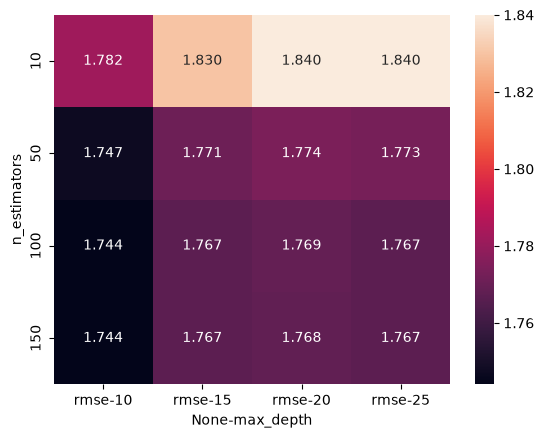

In [44]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

What's the best `max_depth`, using the mean RMSE?

In [36]:
print(mean_rmse)

max_depth
10    1.754
15    1.784
20    1.788
25    1.787
Name: rmse, dtype: float64


In [45]:
best_md = mean_rmse.idxmin()
print(f"Lowest error: max_depth={best_md} with mean RMSE={mean_rmse.min():.3f}")

Lowest error: max_depth=10 with mean RMSE=1.754


# Question 5

We can extract feature importance information from tree-based models. 

At each step of the decision tree learning algorithm, it finds the best split. 
When doing it, we can calculate "gain" - the reduction in impurity before and after the split. 
This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the
[`feature_importances_`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor.feature_importances_)
field. 

For this homework question, we'll find the most important feature:

* Train the model with these parameters:
  * `n_estimators=10`,
  * `max_depth=20`,
  * `random_state=1`,
  * `n_jobs=-1` (optional)
* Get the feature importance information from this model

In [46]:
rf_regr = RandomForestRegressor(
            n_estimators=10,
            max_depth=20,
            random_state=1
        )

rf_regr.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of th

In [51]:
importances = pd.Series(rf_regr.feature_importances_, index=dv.get_feature_names_out())
importances.sort_values(ascending=False).round(3)

model_year                      0.296
vehicle_weight                  0.203
fuel_type=Gasoline              0.161
horsepower                      0.078
engine_displacement             0.061
acceleration                    0.055
origin=USA                      0.042
drivetrain=Front-wheel drive    0.020
num_doors                       0.019
fuel_type=Diesel                0.018
fuel_type=Hybrid                0.015
drivetrain=All-wheel drive      0.008
num_cylinders                   0.007
origin=Asia                     0.006
drivetrain=Rear-wheel drive     0.006
origin=Europe                   0.004
dtype: float64

What's the most important feature (among these 4)? 

In [52]:
print(f"Most important feature: {importances.idxmax()} ({importances.max():.3f})")

Most important feature: model_year (0.296)


In [53]:
print(importances.nlargest(4).round(3))

model_year            0.296
vehicle_weight        0.203
fuel_type=Gasoline    0.161
horsepower            0.078
dtype: float64


## Question 6

Now let's train an XGBoost model! For this question, we'll tune the `eta` parameter:

* Install XGBoost
* Create DMatrix for train and validation
* Create a watchlist
* Train a model with these parameters for 100 rounds:

In [ ]:
xgb_params = {
    'eta': 0.3, # change with different values
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

In [54]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [56]:
from IPython.utils.capture import capture_output

In [57]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [ ]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [63]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [64]:
scores = {}
for eta in [0.1, 0.3]:
    xgb_params['eta'] = eta

    with capture_output() as output:
        model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                          verbose_eval=5, evals=watchlist)

    scores['eta=%s' % eta] = parse_xgb_output(output)

In [66]:
for key, df_res in scores.items():
    print(f"{key}: best val RMSE = {df_res.val_rmse.min():.3f}")

eta=0.1: best val RMSE = 1.713
eta=0.3: best val RMSE = 1.732


Answer: `eta=0.1`. The smaller step size of 0.1 learns more slowly and stays more stable.